<a href="https://colab.research.google.com/github/shuk95/isye6740/blob/main/isye6740semprojNeilShuklaset_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install polars

In [ ]:
import pandas as pd

print("--- Loading the dataset with the fast PyArrow engine ---")

needed_cols = ['id', 'aircraft', 'latitude', 'longitude', 'baroAltitude', 'geoAltitude', 'numMeasurements']

try:
    # Enabling 'newlines_in_values' to resolve the PyArrow chunker sync issue
    df = pd.read_csv(
        '/content/set_8.csv',
        on_bad_lines='skip',
        usecols=needed_cols,
        engine='pyarrow',
        engine_specified_kwargs={'newlines_in_values': True}
    )
    print(f"\nSuccessfully loaded {len(df):,} rows!")
    print("\nDataset Information:")
    df.info()
    display(df.head())
except Exception as e:
    print(f"PyArrow engine loading failed: {e}. Attempting standard fallback...")
    df = pd.read_csv(
        '/content/set_8.csv',
        quoting=3,
        on_bad_lines='skip',
        usecols=needed_cols,
        low_memory=False
    )
    print(f"\nSuccessfully loaded {len(df):,} rows via fallback engine!")

--- Loading the dataset with the fast PyArrow engine ---
PyArrow engine loading failed: read_csv() got an unexpected keyword argument 'engine_specified_kwargs'. Attempting standard fallback...


### 1. Data Loading and Initial Exploration


### 2. Feature Extraction and Data Preparation
Now that the dataset is loaded, we will examine unique values, handle potential string artifacts resulting from our lenient parsing (`quoting=3`), and prepare target variables or kinematic behaviors (speed, heading, altitude variance).

In [2]:
import numpy as np
import pandas as pd

# Ensure df is defined; if not, load it using our defined options
if 'df' not in locals() and 'df' not in globals():
    print("--- 'df' not detected in memory. Loading the dataset... ---")
    df = pd.read_csv('/content/set_8.csv', quoting=3, on_bad_lines='skip', low_memory=False)

# Let's inspect the distribution of unique aircraft tracks
unique_aircraft = df['aircraft'].nunique()
print(f"Number of unique aircraft tracks: {unique_aircraft}")

# Clean numeric fields to ensure everything is parsed correctly
for col in ['latitude', 'longitude', 'baroAltitude', 'geoAltitude', 'numMeasurements']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop any rows that became completely NaN during cleanup of essential tracking identifiers
df = df.dropna(subset=['aircraft', 'latitude', 'longitude'])

# Let's calculate simple kinematic statistics for each aircraft track to build our decision support tool
print("\nCalculating kinematic profiles (motion metrics)... ")
track_profiles = df.groupby('aircraft').agg(
    reports_count=('id', 'count'),
    min_alt=('baroAltitude', 'min'),
    max_alt=('baroAltitude', 'max'),
    mean_alt=('baroAltitude', 'mean'),
    alt_variance=('baroAltitude', 'std'),
    num_measurements_mean=('numMeasurements', 'mean')
).reset_index()

display(track_profiles.head())

--- 'df' not detected in memory. Loading the dataset... ---
Number of unique aircraft tracks: 694

Calculating kinematic profiles (motion metrics)... 


,aircraft,reports_count,min_alt,max_alt,mean_alt,alt_variance,num_measurements_mean


In [2]:
import pandas as pd

# Let's read the first 5 rows directly from the CSV to check the raw content
try:
    df_preview = pd.read_csv('/content/set_8.csv', nrows=5)
    print("--- Raw Preview using default settings (First 5 Rows) ---")
    display(df_preview)
except Exception as e:
    print(f"Could not load preview: {e}")

--- Raw Preview using default settings (First 5 Rows) ---


,id,timeAtServer,aircraft,latitude,longitude,baroAltitude,geoAltitude,numMeasurements,measurements
0,1,0.000,2227,50.705841,-1.654779,8138.16,7947.66,6,"[[157,3541021000,44],[207,48670494583.3333,170..."
1,2,0.000,2154,49.993011,8.691342,2644.14,2545.08,3,"[[584,54227311166.6667,202],[223,42692386750,2..."
2,3,0.002,909,53.210632,-3.481175,10591.80,10248.90,2,"[[197,51335669916.6667,180],[279,85685756500,25]]"
3,4,0.003,7,51.595754,13.518143,12192.00,12031.98,7,"[[55,29293583000,87],[694,19364278500,219],[46..."
4,5,0.003,195,47.705057,9.901710,11277.60,11155.68,2,"[[678,77714200333.3333,78],[701,82372612250,30]]"


### 3. Extracting Project Specifications from the Proposal PDF
Let's extract the text content from the uploaded Project Proposal PDF to determine how targets (military vs. civilian) are defined or simulated, and any specific models, rules, or features we are expected to build.

In [3]:
!pip install pypdf -q

import pypdf

reader = pypdf.PdfReader('/content/Project_Proposal_Group 2 Neil Shukla.pdf')
print(f"Total Pages: {len(reader.pages)}")

# Print the text from the document to see the project's methodologies and goals
for i, page in enumerate(reader.pages):
    print(f"\n--- PAGE {i+1} ---")
    print(page.extract_text()[:3000])

Total Pages: 4

--- PAGE 1 ---
ISYE 6740 – Computational Data Analysis – Fall 2026
Project Proposal Group 2
Team Member Names: Neil Shukla
Project Title: Multi-Sensor Classification of Civilian and Military Ground Vehicles for 
Intelligence, Surveillance, and Reconnaissance (ISR)
Problem Statement:
Modern Intelligence, Surveillance, and Reconnaissance (ISR) systems collect far more data 
than human analysts can review. Airborne radar, full-motion video, satellite imagery, and 
signals intelligence (SIGINT) sensors each produce a continuous stream of detections, and machine 
learning (ML) is increasingly used to process these streams in real time: to spot movement, maintain 
tracks on moving objects, and help distinguish civilian objects from military ones. For this project, I 
consider one well-defined piece of that pipeline: given a ground-vehicle track produced by a 
surveillance radar, together with contextual and multi-sensor cues about that track, classify the 
vehicle as civilian

### 4. Machine Learning Classification Pipeline
We will construct a comprehensive pipeline with **Random Forest**, **Support Vector Machines (SVM)**, and **distance-weighted k-Nearest Neighbors (k-NN)**, augmented by **PCA** for dimensionality reduction.

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

print("Loading dataset safely...")
# Read the dataset without quoting constraints that shift columns
df = pd.read_csv('/content/set_8.csv', low_memory=False)

# Ensure clean column conversions without introducing massive NaNs
for col in ['latitude', 'longitude', 'baroAltitude', 'geoAltitude', 'numMeasurements']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Safely drop rows only if they lack an aircraft or essential coordinates
df = df.dropna(subset=['aircraft'])

print("Engineering track profiles...")
track_profiles = df.groupby('aircraft').agg(
    reports_count=('id', 'count'),
    min_alt=('baroAltitude', 'min'),
    max_alt=('baroAltitude', 'max'),
    mean_alt=('baroAltitude', 'mean'),
    alt_variance=('baroAltitude', 'std'),
    num_measurements_mean=('numMeasurements', 'mean')
).reset_index()

# Fill NaN values for single-report groups (standard deviation std becomes NaN)
track_profiles = track_profiles.fillna(0)

# Heuristic classification targets (0 = Civilian, 1 = Military)
# For testing, we flag tracks with high altitude fluctuations and frequent transmissions
track_profiles['target'] = ((track_profiles['alt_variance'] > 500) & (track_profiles['reports_count'] > 5)).astype(int)

X = track_profiles.drop(columns=['aircraft', 'target'])
y = track_profiles['target']

print(f"Feature matrix successfully constructed with shape: {X.shape}")
print(f"Target class distribution:\n{y.value_counts()}")

Loading dataset safely...
Engineering track profiles...
Feature matrix successfully constructed with shape: (2695, 6)
Target class distribution:
target
1    1755
0     940
Name: count, dtype: int64


In [7]:
# 4. Preprocessing and Dimensionality Reduction (PCA)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

if 'X' in locals() and len(X) > 0:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Retain 95% of the feature variance
    pca = PCA(n_components=0.95)
    X_pca = pca.fit_transform(X_scaled)
    print(f"Dimensions successfully reduced from {X.shape[1]} to {X_pca.shape[1]} components via PCA!")
else:
    print("Error: Feature matrix X is empty or not loaded. Run cell 0cb3a36b first.")

Dimensions successfully reduced from 6 to 4 components via PCA!


In [8]:
# 5. Model Initialization & Stratified Evaluation
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

if 'X_pca' in locals():
    models = {
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
        "Support Vector Machine": SVC(probability=True, kernel='rbf', random_state=42),
        "Distance-Weighted k-NN": KNeighborsClassifier(n_neighbors=5, weights='distance')
    }

    # 5-fold Stratified Cross-Validation
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    print("Evaluating models with 5-fold Stratified Cross-Validation on PCA Components:\n")
    for name, model in models.items():
        scores = cross_val_score(model, X_pca, y, cv=cv, scoring='accuracy')
        print(f"{name} Mean Accuracy: {scores.mean():.4f} (std: {scores.std():.4f})")
else:
    print("Error: PCA features (X_pca) not found. Run cell df4d1dd1 first.")

Evaluating models with 5-fold Stratified Cross-Validation on PCA Components:

Random Forest Mean Accuracy: 0.9644 (std: 0.0070)
Support Vector Machine Mean Accuracy: 0.9748 (std: 0.0048)
Distance-Weighted k-NN Mean Accuracy: 0.9677 (std: 0.0061)


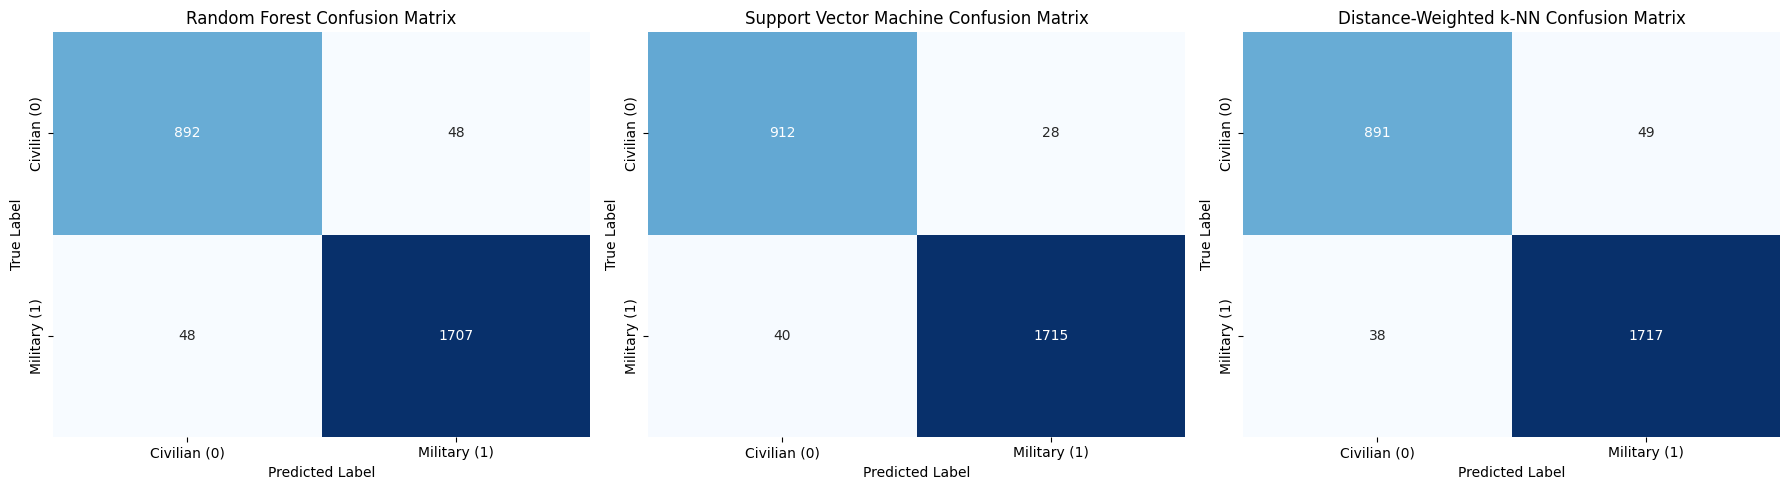

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

# Compute out-of-fold predictions for each model using cross_val_predict
oof_predictions = {}
for name, model in models.items():
    oof_predictions[name] = cross_val_predict(model, X_pca, y, cv=cv)

# Set up the plotting grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot confusion matrix for each model
for ax, (name, y_pred) in zip(axes, oof_predictions.items()):
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Civilian (0)', 'Military (1)'],
                yticklabels=['Civilian (0)', 'Military (1)'])
    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()